A serial position curve shows how often participants recall an item as a function of its position on the study list. A recall at any output position counts.

## Choose the lists to compare

List each response file once and give it a label. Write one trial query per condition using fields shared by the files, and supply the condition names in the same order. To use all eligible lists as one condition, set `trial_queries = [None]` and `labels = ["All lists"]`.


In [1]:
#| code-summary: "Select datasets, conditions and outputs"

data_paths = ["data/Dupertuys2026.h5"]
data_labels = ["Observed"]
trial_queries = ["data['list_type'] == 1", "data['list_type'] == 2", "data['list_type'] == 3"]
labels = ["Mixed", "Pure emotional", "Pure neutral"]
# Use "datasets" for one figure per condition or "conditions" to overlay conditions from one file.
comparison = "datasets"
complete_lists_only = True
max_subjects = 0              # Zero includes all participants.
confidence_level = 0.95
plot_seed = 0

project_root = None
output_dir = "results/spc"
figure_dir = None             # Defaults to output_dir.
figure_str = "spc"            # An empty name displays figures without saving.

# Optional plot settings for parameterized runs.
color_cycle = None
contrast_name = None
ylim = (0, 1)
yticks = None

## Load the responses

Relative paths use the project directory. The [data guide](https://githubpsyche.github.io/jaxcmr/overview/data.html) describes the expected file format.

In [2]:
#| code-summary: "Install JAXCMR in Colab"

import sys

if "google.colab" in sys.modules:
    %pip install --upgrade "jaxcmr @ git+https://github.com/githubpsyche/jaxcmr.git@main"


In [3]:
#| code-summary: "Import plotting and dataset operations"

import re

import matplotlib.pyplot as plt

from jaxcmr.analyses.spc import plot_spc
from jaxcmr.dataset import select_conditions
from jaxcmr.examples import copy_example_inputs
from jaxcmr.helpers import load_data, resolve_project_path, resolve_project_root
from jaxcmr.plotting import comparison_panels, save_figure

In [4]:
#| code-summary: "Load response files"

root = resolve_project_root(project_root)
copy_example_inputs(data_paths, base_dir=root)
datasets = [load_data(resolve_project_path(path, root), max_subjects=max_subjects) for path in data_paths]

## Select the trials

With `complete_lists_only=True`, the selection excludes any trial with a padded study position. This includes shorter lists stored alongside longer ones.


In [5]:
#| code-summary: "Select trials for each condition"

masks_by_dataset = []
for dataset in datasets:
    selections = select_conditions(dataset, trial_queries, complete_lists_only=complete_lists_only)
    masks_by_dataset.append([selection.mask for selection in selections])

## Recall by study position

Each point is the mean of the participants’ recall probabilities at that position. Error bars show bootstrap confidence intervals for that mean. If an item appeared more than once on a list, recalling it credits each of its study positions once.

When saving several figures, the notebook adds the condition number and label to each filename. A single figure uses `figure_str` alone.


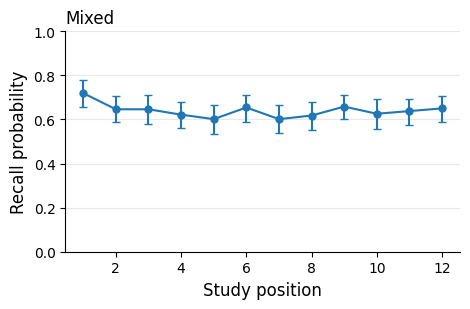

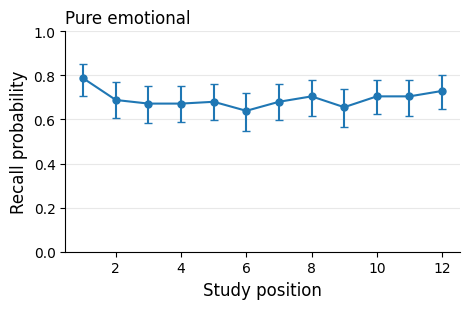

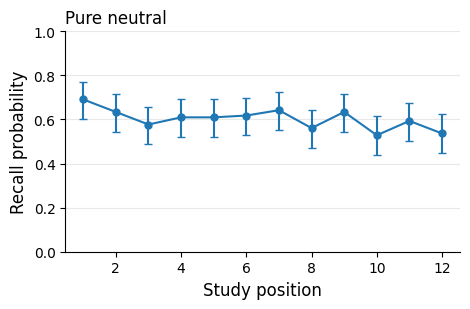

In [6]:
#| code-summary: "Plot and save each comparison"

panels = comparison_panels(
    datasets, masks_by_dataset, data_labels, labels, mode=comparison
)
for number, panel in enumerate(panels, start=1):
    fig, ax = plt.subplots(figsize=(4.8, 3.2))
    plot_spc(panel["datasets"], panel["trial_masks"], axis=ax, labels=panel["labels"],
             color_cycle=color_cycle, confidence_level=confidence_level, bootstrap_seed=plot_seed)

    title = data_labels[0] if comparison == "conditions" else panel["title"]
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_xlabel("Study position", fontsize=12)
    ax.set_ylabel("Recall probability", fontsize=12)
    ax.tick_params(labelsize=10)
    ax.set_ylim(ylim)
    if yticks is not None:
        ax.set_yticks(yticks)
    if len(panel["labels"]) > 1:
        ax.legend(title=contrast_name, frameon=False)

    if figure_str:
        suffix = None
        if len(panels) > 1:
            label = re.sub(r"\W+", "_", panel["title"].casefold()).strip("_")
            suffix = f"{number}_{label}".rstrip("_")
        save_figure(resolve_project_path(figure_dir or output_dir, root), figure_str,
                    suffix=suffix, figure=fig)
    else:
        fig.tight_layout()
    plt.show()
    plt.close(fig)